In [1]:
#Imports, load the data and keep SITE_001

import pandas as pd
import numpy as np
import sys
import os

sys.path.append('../')
from src.data_loader import load_cement_data
from src.metrics import print_metrics

import warnings
warnings.filterwarnings('ignore')

df = load_cement_data()

site_id = 'SITE_001'
site_df = df[df['site_id'] == site_id].copy()
site_df.set_index('date', inplace=True)
site_df = site_df.sort_index()

site_df.shape

(1096, 12)

In [2]:
#Lag features (recent usage)
site_df['lag_1'] = site_df['consumed_tonnes'].shift(1)
site_df['lag_3'] = site_df['consumed_tonnes'].shift(3)
site_df['lag_7'] = site_df['consumed_tonnes'].shift(7)

In [3]:
#Rolling features (fixed to avoid the leak)
site_df['rolling_mean_3'] = site_df['consumed_tonnes'].shift(1).rolling(3).mean()
site_df['rolling_std_7'] = site_df['consumed_tonnes'].shift(1).rolling(7).std()

In [4]:
#Calendar features
site_df['day_of_week'] = site_df.index.dayofweek
site_df['week_of_year'] = site_df.index.isocalendar().week.astype(int)
site_df['month'] = site_df.index.month

In [5]:
#Weather × pour and inventory features

site_df['rain_x_pour'] = site_df['rain_mm'] * site_df['planned_pour_tonnes']
site_df['temp_x_pour'] = site_df['avg_temp_c'] * site_df['planned_pour_tonnes']

site_df['inventory_gap'] = (site_df['opening_inventory_tonnes']
                            + site_df['deliveries_tonnes']
                            - site_df['planned_pour_tonnes'])

site_df['inventory_ratio'] = np.where(
    site_df['silo_capacity'] > 0,
    site_df['opening_inventory_tonnes'] / site_df['silo_capacity'],
    np.nan
)

In [6]:
#Remove the first rows with missing lag values

site_df.dropna(inplace=True)
site_df.shape


(1089, 24)

In [7]:
#Choose the inputs and split

features = ['planned_pour_tonnes', 'rain_mm', 'avg_temp_c',
            'lag_1', 'lag_3', 'lag_7', 'rolling_mean_3', 'rolling_std_7',
            'day_of_week', 'week_of_year', 'month',
            'rain_x_pour', 'temp_x_pour', 'inventory_gap', 'inventory_ratio']

X = site_df[features]
y = site_df['consumed_tonnes']

split_index = int(len(site_df) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Training:", len(X_train), "days | Testing:", len(X_test), "days")

Training: 871 days | Testing: 218 days


In [8]:
#AdaBoost with the new features

from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

ada = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=200,
    learning_rate=0.1,
    random_state=42
)
ada.fit(X_train, y_train)

ada_forecast = ada.predict(X_test)
print_metrics(y_test, ada_forecast, 'AdaBoost Engineered')

AdaBoost Engineered - MAPE: 11.77%, RMSE: 4.04 tonnes


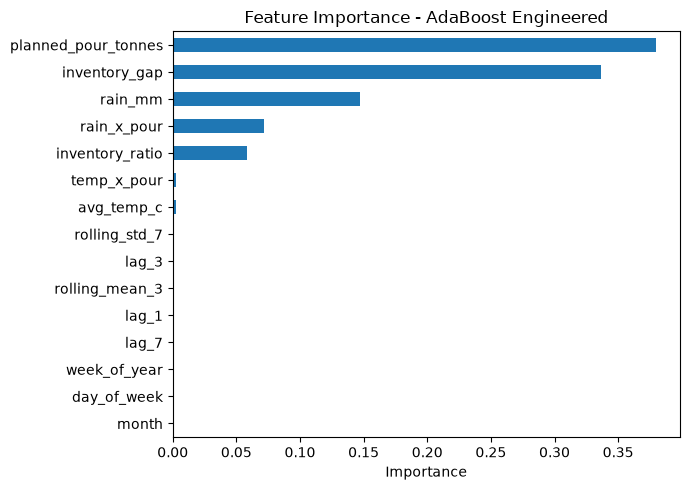

In [9]:
#Which features mattered most?
import matplotlib.pyplot as plt

importance = pd.Series(ada.feature_importances_, index=features).sort_values()

importance.plot(kind='barh', figsize=(7, 5), title='Feature Importance - AdaBoost Engineered')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [10]:
#Test a simpler model with only the 5 useful features
top_features = ['planned_pour_tonnes', 'inventory_gap', 'rain_mm', 'rain_x_pour', 'inventory_ratio']

ada_simple = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=200,
    learning_rate=0.1,
    random_state=42
)
ada_simple.fit(X_train[top_features], y_train)

ada_simple_forecast = ada_simple.predict(X_test[top_features])
print_metrics(y_test, ada_simple_forecast, 'AdaBoost (5 features)')

AdaBoost (5 features) - MAPE: 11.86%, RMSE: 4.38 tonnes


In [11]:
#Forecast vs actual chart (engineered model)

import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=y_test.index, y=y_test, mode='lines',
                         name='Actual', line=dict(color='black')))
fig.add_trace(go.Scatter(x=y_test.index, y=ada_forecast, mode='lines',
                         name='AdaBoost Engineered forecast', line=dict(color='red')))

fig.update_layout(
    title=f'AdaBoost Engineered Forecast vs Actual - {site_id}',
    xaxis_title='Date',
    yaxis_title='Cement Consumed (tonnes)',
    legend=dict(x=0, y=1),
    template='plotly_white',
    width=1000,
    height=450
)
fig.show()

## Inventory Simulation

In [12]:
#What actually happened (the benchmark)
test_period = site_df.loc[y_test.index]
silo_capacity = test_period['silo_capacity'].iloc[0]

hist_stockout = (test_period['planned_pour_tonnes']
                 > test_period['opening_inventory_tonnes'] + test_period['deliveries_tonnes'])
hist_overstock = test_period['closing_inventory_tonnes'] > silo_capacity

print("Silo capacity:", silo_capacity, "tonnes")
print("Test days:", len(test_period))
print("Actual stockout days:", hist_stockout.sum())
print("Actual overstock days:", hist_overstock.sum())
print("Actual delivery days:", (test_period['deliveries_tonnes'] > 0).sum())
print("Average closing stock:", round(test_period['closing_inventory_tonnes'].mean(), 1), "tonnes")

Silo capacity: 448 tonnes
Test days: 218
Actual stockout days: 106
Actual overstock days: 0
Actual delivery days: 218
Average closing stock: 18.9 tonnes


In [13]:
#Simulate forecast-based ordering
reorder_threshold = 0.2 * silo_capacity
target_inventory = 0.8 * silo_capacity
lead_time_days = 2
buffer_rain_threshold = 10
buffer_increase = 0.1

df_sim = pd.DataFrame({
    'forecast': ada_forecast,
    # On days the site actually ran out, it needed its planned pour, not the reduced amount it used
    'demand': np.where(hist_stockout, test_period['planned_pour_tonnes'], y_test),
    'rain_mm': X_test['rain_mm'].values,
}, index=y_test.index)

inventory = test_period['opening_inventory_tonnes'].iloc[0]
delivery_queue = {}
rows = []

for i, today in enumerate(df_sim.index):
    # 1. Receive any delivery due today (silo can't overflow)
    inventory = min(inventory + delivery_queue.pop(today, 0), silo_capacity)

    # 2. Use cement: actual demand, but never more than is in the silo
    demand = df_sim.loc[today, 'demand']
    used = min(demand, inventory)
    unmet = demand - used
    inventory -= used

    # 3. Use the FORECAST to look ahead until a new order could arrive
    upcoming = df_sim['forecast'].iloc[i + 1:i + 1 + lead_time_days].sum()
    on_order = sum(delivery_queue.values())
    projected = inventory + on_order - upcoming

    # 4. Order only if projected stock falls below the reorder level
    order = 0.0
    if projected < reorder_threshold:
        order = target_inventory - projected
        if df_sim.loc[today, 'rain_mm'] > buffer_rain_threshold:
            order *= (1 + buffer_increase)
        order = max(0, min(order, silo_capacity - inventory - on_order))
        if order > 0:
            arrival = today + pd.Timedelta(days=lead_time_days)
            delivery_queue[arrival] = delivery_queue.get(arrival, 0) + order

    rows.append({'date': today, 'closing_stock': inventory, 'used': used,
                 'unmet': unmet, 'order_qty': order})

sim = pd.DataFrame(rows).set_index('date')

print("Simulated stockout days:", (sim['unmet'] > 0).sum())
print("Unmet demand:", round(sim['unmet'].sum(), 1), "tonnes")
print("Orders placed:", (sim['order_qty'] > 0).sum())
print("Average closing stock:", round(sim['closing_stock'].mean(), 1), "tonnes")
print("Days above 85% full:", (sim['closing_stock'] > 0.85 * silo_capacity).sum())

Simulated stockout days: 1
Unmet demand: 40.3 tonnes
Orders placed: 29
Average closing stock: 218.2 tonnes
Days above 85% full: 1


In [14]:
#Can we hold less stock and still avoid stockouts
print(f"{'Target':>8} {'Stockouts':>10} {'Orders':>7} {'Avg stock':>10}")
for target_pct in [0.8, 0.6, 0.4, 0.3]:
    target_inventory = target_pct * silo_capacity
    inventory = test_period['opening_inventory_tonnes'].iloc[0]
    delivery_queue = {}
    stockouts, orders, stock = 0, 0, []

    for i, today in enumerate(df_sim.index):
        inventory = min(inventory + delivery_queue.pop(today, 0), silo_capacity)
        demand = df_sim.loc[today, 'demand']
        if demand > inventory:
            stockouts += 1
        inventory -= min(demand, inventory)
        upcoming = df_sim['forecast'].iloc[i + 1:i + 1 + lead_time_days].sum()
        on_order = sum(delivery_queue.values())
        projected = inventory + on_order - upcoming
        if projected < reorder_threshold:
            order = target_inventory - projected
            if df_sim.loc[today, 'rain_mm'] > buffer_rain_threshold:
                order *= (1 + buffer_increase)
            order = max(0, min(order, silo_capacity - inventory - on_order))
            if order > 0:
                arrival = today + pd.Timedelta(days=lead_time_days)
                delivery_queue[arrival] = delivery_queue.get(arrival, 0) + order
                orders += 1
        stock.append(inventory)

    print(f"{target_pct:>8.0%} {stockouts:>10} {orders:>7} {np.mean(stock):>10.1f}")

target_inventory = 0.8 * silo_capacity   # restore the class setting

  Target  Stockouts  Orders  Avg stock
     80%          1      29      218.2
     60%          1      42      174.8
     40%          1      74      125.6
     30%          1     123      101.9


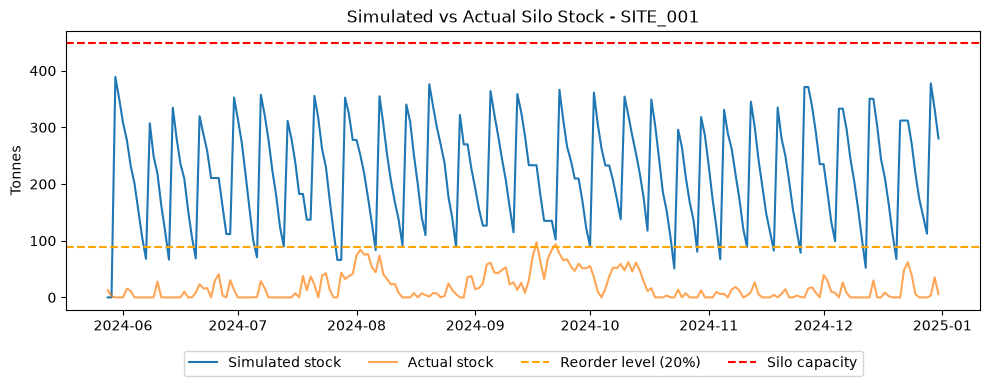

In [16]:
#Chart of simulated stock (with the class’s 80% setting)
plt.figure(figsize=(10, 4))
plt.plot(sim.index, sim['closing_stock'], label='Simulated stock')
plt.plot(test_period.index, test_period['closing_inventory_tonnes'], label='Actual stock', alpha=0.7)
plt.axhline(reorder_threshold, color='orange', linestyle='--', label='Reorder level (20%)')
plt.axhline(silo_capacity, color='red', linestyle='--', label='Silo capacity')
plt.title(f'Simulated vs Actual Silo Stock - {site_id}')
plt.ylabel('Tonnes')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4)
plt.tight_layout()
plt.savefig('../reports/inventory_simulation_site001.png', dpi=200)
plt.show()